# Olist E-commerce Analysis: Revenue, Delivery Performance and Customer Retention

**Author:** Vishnu Vardhan Reddy M R &nbsp;|&nbsp; B.E. CSE (Data Science), Acharya Institute of Technology

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): about 100,000 real, anonymised orders placed on the Olist marketplace between 2016 and 2018 (delivered orders run from September 2016 to August 2018).

**Business questions**

1. How did orders and revenue grow over time?
2. Which product categories drive revenue?
3. Where are deliveries slowest and most often late?
4. Does late delivery hurt customer reviews?
5. How many customers come back?
6. How do customers pay?

**Approach:** the 8 CSV files are loaded into a SQLite database, each question is answered with one SQL query (`sql/analysis_queries.sql`), and the results are visualised with pandas and matplotlib. Revenue means product price (excluding freight) on delivered orders, in Brazilian reais (R$).

In [1]:
import re
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from build_db import build

DB = ROOT / "data" / "olist.db"
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

if not DB.exists():
    build(DB)
con = sqlite3.connect(DB)

# Load every named query from the .sql file into a dictionary
sql_text = (ROOT / "sql" / "analysis_queries.sql").read_text()
QUERIES = {m.group(1): m.group(2).strip()
           for m in re.finditer(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", sql_text, re.S)}

def run(name):
    return pd.read_sql(QUERIES[name], con)

# Chart style: one blue for data, one orange for the point being made, grey for context
BLUE, ORANGE, GREY = "#2E6DB4", "#D9822B", "#B8C2CC"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
print("Queries loaded:", list(QUERIES))

Queries loaded: ['overview', 'monthly_trend', 'category_pareto', 'state_delivery', 'late_vs_reviews', 'repeat_customers', 'payments']


## Data quality checks
Before analysing, check the order statuses, the date range and missing values in the delivery dates.

In [2]:
orders = pd.read_sql("SELECT * FROM orders", con, parse_dates=[
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
print(orders["order_status"].value_counts(), "\n")
print("Purchase dates:", orders["order_purchase_timestamp"].min().date(), "to",
      orders["order_purchase_timestamp"].max().date())
delivered = orders[orders["order_status"] == "delivered"]
print("Delivered orders missing a delivery date:", delivered["order_delivered_customer_date"].isna().sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Purchase dates: 2016-09-04 to 2018-10-17
Delivered orders missing a delivery date: 8


97% of orders have the status *delivered*; the analysis uses only those so that cancelled or unfinished orders do not distort revenue. 8 delivered orders have no delivery date and are dropped from the delivery questions. The months before January 2017 contain very few orders, so the trend starts from 2017.

## Headline numbers

In [3]:
run('overview')

,delivered_orders,unique_customers,revenue_brl,avg_order_value_brl
0,96478,93358,13221498.0,159.83


## Q1. How did orders and revenue grow over time?

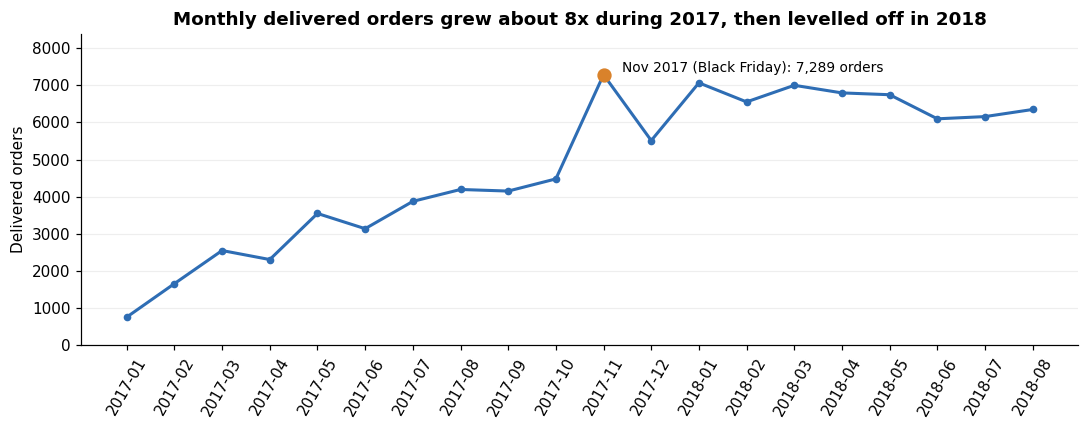

Nov 2017 vs Oct 2017: +63%


In [4]:
monthly = run("monthly_trend")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly["month"], monthly["orders"], color=BLUE, lw=2, marker="o", ms=4)
peak = monthly.loc[monthly["orders"].idxmax()]
ax.scatter(peak["month"], peak["orders"], color=ORANGE, s=70, zorder=3)
ax.annotate(f"Nov 2017 (Black Friday): {peak['orders']:,} orders",
            (peak["month"], peak["orders"]), xytext=(12, 2), textcoords="offset points", fontsize=9)
ax.set_ylim(0, monthly["orders"].max() * 1.15)
ax.set_title("Monthly delivered orders grew about 8x during 2017, then levelled off in 2018")
ax.set_ylabel("Delivered orders")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", color="#EEE")
plt.tight_layout(); plt.savefig(IMG / "01_monthly_orders.png", bbox_inches="tight"); plt.show()

oct17 = monthly.set_index("month").loc["2017-10", "orders"]
print(f"Nov 2017 vs Oct 2017: {peak['orders'] / oct17 - 1:+.0%}")

**Insight:** orders grew from 750 in January 2017 to more than 6,000 a month in 2018. November 2017 was the single biggest month (7,289 orders, +63% over October) because of Black Friday. In 2018, growth flattened at roughly 6,000–7,000 orders a month, so future growth must come from new markets or from more repeat customers rather than from the same trend continuing.

## Q2. Which product categories drive revenue?

18 categories reach 80% of revenue; 73 named categories in total


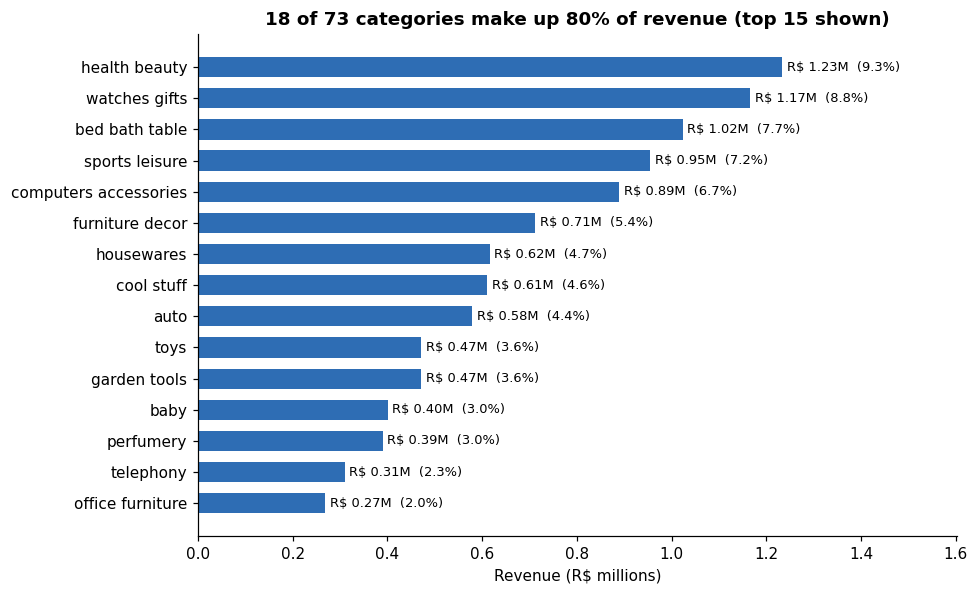

,category,revenue_brl,orders,share_pct,cumulative_share_pct,revenue_rank
0,health_beauty,1233132.0,8647,9.3,9.3,1
1,watches_gifts,1166177.0,5495,8.8,18.1,2
2,bed_bath_table,1023435.0,9272,7.7,25.9,3
3,sports_leisure,954853.0,7530,7.2,33.1,4
4,computers_accessories,888725.0,6530,6.7,39.8,5
5,furniture_decor,711928.0,6307,5.4,45.2,6
6,housewares,615629.0,5743,4.7,49.9,7
7,cool_stuff,610204.0,3559,4.6,54.5,8
8,auto,578967.0,3810,4.4,58.9,9
9,toys,471286.0,3804,3.6,62.4,10


In [5]:
cats = run("category_pareto")
named = cats[cats["category"] != "uncategorised"]
n80 = int((cats["cumulative_share_pct"] < 80).sum() + 1)
print(f"{n80} categories reach 80% of revenue; {len(named)} named categories in total")
top = cats.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["category"].str.replace("_", " "), top["revenue_brl"] / 1e6, color=BLUE, height=0.65)
for y, (v, s) in enumerate(zip(top["revenue_brl"] / 1e6, top["share_pct"])):
    ax.text(v + 0.01, y, f"R$ {v:.2f}M  ({s:.1f}%)", va="center", fontsize=8.5)
ax.set_title(f"{n80} of {len(named)} categories make up 80% of revenue (top 15 shown)")
ax.set_xlabel("Revenue (R$ millions)")
ax.set_xlim(0, top["revenue_brl"].max() / 1e6 * 1.3)
plt.tight_layout(); plt.savefig(IMG / "02_category_revenue.png", bbox_inches="tight"); plt.show()
cats.head(10)

**Insight:** revenue is concentrated. 18 of the 73 categories bring in 80% of revenue. Health & beauty (9.3%), watches & gifts (8.8%) and bed, bath & table (7.7%) lead. Watches & gifts earns almost as much as health & beauty from far fewer orders, so it has a much higher value per order, which makes it a good category for premium promotions.

## Q3. Where are deliveries slowest and most often late?

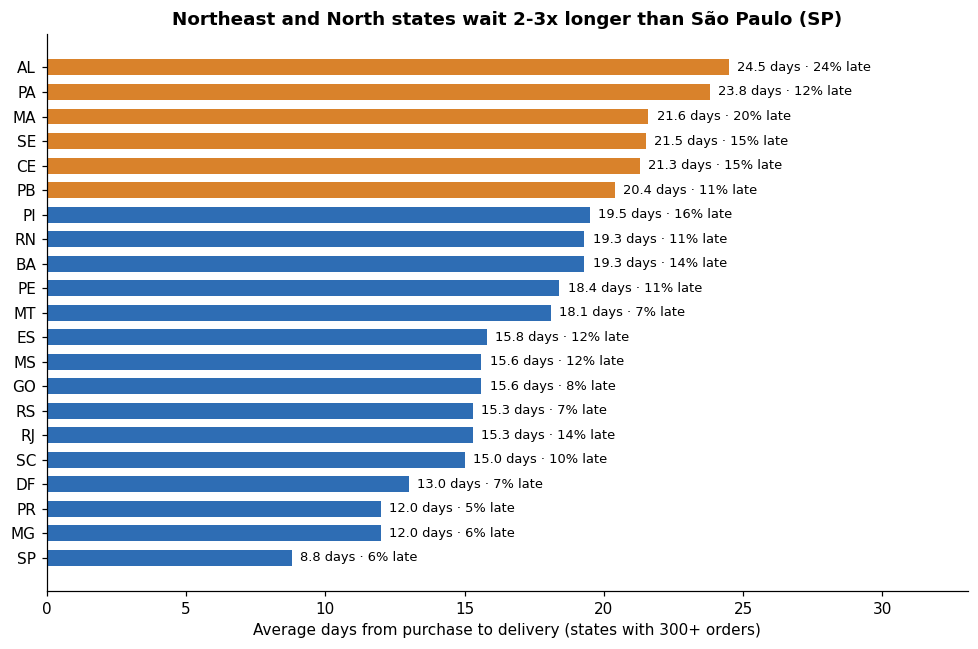

In [6]:
states = run("state_delivery").sort_values("avg_delivery_days")
colors = [ORANGE if d >= 20 else BLUE for d in states["avg_delivery_days"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(states["state"], states["avg_delivery_days"], color=colors, height=0.65)
for y, (d, l) in enumerate(zip(states["avg_delivery_days"], states["late_pct"])):
    ax.text(d + 0.3, y, f"{d:.1f} days · {l:.0f}% late", va="center", fontsize=8.5)
ax.set_title("Northeast and North states wait 2-3x longer than São Paulo (SP)")
ax.set_xlabel("Average days from purchase to delivery (states with 300+ orders)")
ax.set_xlim(0, states["avg_delivery_days"].max() * 1.35)
plt.tight_layout(); plt.savefig(IMG / "03_delivery_by_state.png", bbox_inches="tight"); plt.show()

**Insight:** a customer in São Paulo (SP), where most sellers are based, waits 8.8 days on average. Customers in the North and Northeast wait 2–3 times longer: Alagoas (AL) averages 24.5 days and 24% of its orders arrive after the promised date. Rio de Janeiro (RJ) is a surprise: it is close to SP but 13.5% of its orders are late, more than twice SP's rate.

## Q4. Does late delivery hurt customer reviews?

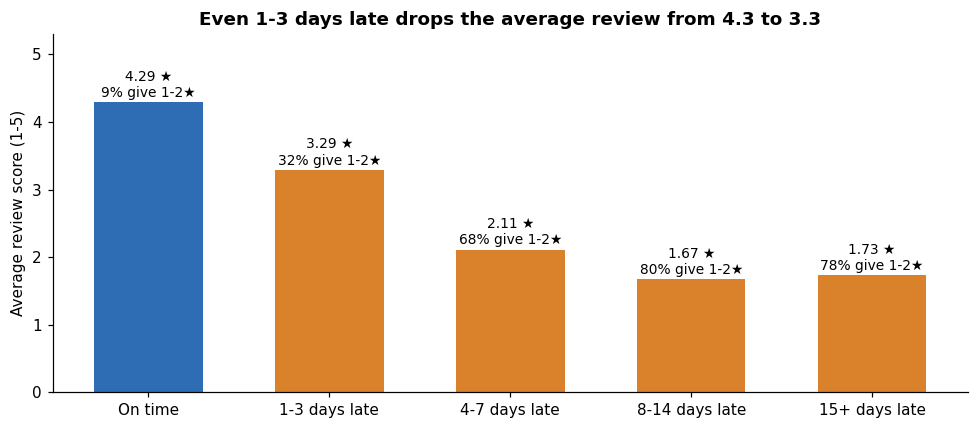

,delivery_bucket,orders,avg_review,pct_1_or_2_star
0,1. On time,89443,4.29,9.2
1,2. 1-3 days late,1852,3.29,32.2
2,3. 4-7 days late,1748,2.11,67.6
3,4. 8-14 days late,1446,1.67,80.1
4,5. 15+ days late,1335,1.73,78.2


In [7]:
lr = run("late_vs_reviews")
labels = lr["delivery_bucket"].str[3:]
colors = [BLUE] + [ORANGE] * (len(lr) - 1)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, lr["avg_review"], color=colors, width=0.6)
for b, v, p in zip(bars, lr["avg_review"], lr["pct_1_or_2_star"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.08, f"{v:.2f} ★\n{p:.0f}% give 1-2★",
            ha="center", fontsize=9)
ax.set_ylim(0, 5.3)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Even 1-3 days late drops the average review from 4.3 to 3.3")
plt.tight_layout(); plt.savefig(IMG / "04_late_vs_reviews.png", bbox_inches="tight"); plt.show()
lr

**Insight:** this is the most important finding. On-time orders average 4.29 stars and only 9% get a 1–2 star review. Being just 1–3 days late drops the average to 3.29, and at 4–7 days late, two out of three customers (68%) leave a 1–2 star review. Delivery reliability, not the product itself, is the biggest driver of bad reviews.

## Q5. How many customers come back?

In [8]:
run('repeat_customers')

,orders_per_customer,customers,pct_customers
0,1,90557,97.00
1,2,2573,2.76
2,3+,228,0.24


**Insight:** 97% of the 93,358 customers ordered only once in two years, and only 3% came back. Olist depends almost entirely on new customers. Combined with Q4, poor delivery experiences are a likely reason that customers do not return.

## Q6. How do customers pay?

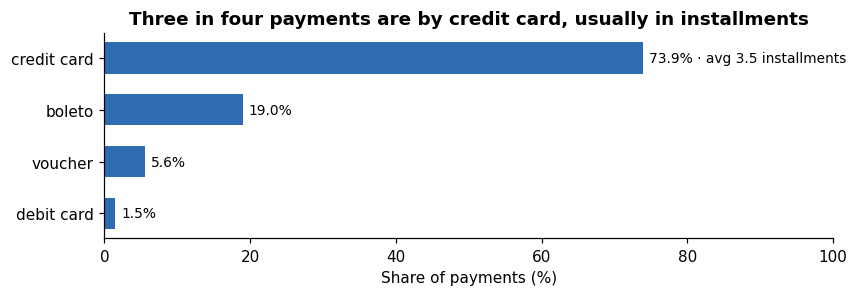

In [9]:
pay = run("payments").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(pay["payment_type"].str.replace("_", " "), pay["share_pct"], color=BLUE, height=0.6)
for y, (s, n) in enumerate(zip(pay["share_pct"], pay["avg_installments"])):
    ax.text(s + 0.8, y, f"{s:.1f}%" + (f" · avg {n:.1f} installments" if n > 1 else ""), va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("Share of payments (%)")
ax.set_title("Three in four payments are by credit card, usually in installments")
plt.tight_layout(); plt.savefig(IMG / "05_payments.png", bbox_inches="tight"); plt.show()

**Insight:** credit cards are used for 74% of payments, split into 3.5 installments on average, and *boleto* (a bank payment slip popular in Brazil) for 19%. Showing the installment price prominently on product pages is likely to matter for conversion.

## Recommendations

1. **Make delivery promises realistic, region by region.** Late delivery is the strongest driver of 1–2 star reviews. Set longer estimated dates for North and Northeast states, and send customers a proactive update when an order is running late.
2. **Fix the RJ and Northeast carrier performance.** Rio de Janeiro is late 13.5% of the time despite being close to São Paulo; review carrier contracts there and consider a regional warehouse for the Northeast.
3. **Start a retention programme.** Only 3% of customers return. A second-order coupon sent after a good (on-time, 4–5 star) delivery is a low-cost first test.
4. **Prepare for Black Friday.** November 2017 brought 63% more orders than October. Plan seller stock and carrier capacity from September.
5. **Promote the top categories and installments.** 18 categories make 80% of revenue; feature them in campaigns and show the installment price clearly.

## Limitations

- The data covers one marketplace in Brazil from 2016 to 2018, so the patterns may differ in other markets or years.
- Reviews show correlation with late delivery, not proof of causation; a controlled test would be needed to measure the exact effect.
- Revenue excludes freight and cancelled orders by design.